# **GIẢI PHÁP: PHÂN TÍCH ABC DANH MỤC SẢN PHẨM ECOMMERCE**

### **Quy trình xử lý dữ liệu**

Để thực hiện phân tích này, chúng ta cần đi qua 4 giai đoạn chính:

1. **Hợp nhất (Join):** Kết nối bảng `EcomSales` và `Product` để có tên sản phẩm cụ thể.
2. **Tính toán (Calculation):** Gom nhóm lợi nhuận và tính toán tỷ lệ % tích lũy.
3. **Phân loại (Labeling):** Sử dụng `np.select()` để dán nhãn A, B, C theo ngưỡng 80% - 95%.
4. **Thống kê (Aggregation):** Tính toán mật độ để đưa ra kết luận quản trị.

# **1. Import thư viện**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Cấu hình hiển thị
sns.set_theme(style="white")
plt.rcParams['figure.figsize'] = (14, 7)

# **2. Tiền xử lý và Làm sạch Dữ liệu**
Trong bước này, chúng ta sẽ tải dữ liệu, kiểm tra tính toàn vẹn của dữ liệu và thực hiện các bước biến đổi dữ liệu cần thiết.

## **2.1. Tải tập dữ liệu**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Tải các bảng dữ liệu
products = pd.read_csv('/content/drive/MyDrive/K04 - Scripts các buổi học/Dataset/Buổi 4: Phân tích ABC/Product.csv')
sales = pd.read_csv('/content/drive/MyDrive/K04 - Scripts các buổi học/Dataset/Buổi 4: Phân tích ABC/EcomSales.csv')

print("Dữ liệu đã sẵn sàng!")

Dữ liệu đã sẵn sàng!


## **2.2. Kiểm tra thông tin tổng quát**
Kiểm tra cấu trúc, kiểu dữ liệu, các giá trị thiếu (null) và bản ghi trùng lặp.

In [ ]:
# Defind function
def check_dataframe(df: pd.DataFrame, outlier_threshold: float = 1.5) -> None:
    """Kiểm tra tổng thể một DataFrame bao gồm:

    1. Metadata (df.info)
    2. Data types
    3. Duplicate rows
    4. Missing values (NA)
    5. Outliers (phương pháp IQR cho biến định lượng)
    """
    print("=" * 60)
    print("1. DF METADATA & DATA TYPES")
    print("=" * 60)
    print(f"- Shape: {df.shape[0]} hàng x {df.shape[1]} cột\n")

    # Bảng tổng hợp Type, Missing values và Unique values
    type_na_df = pd.DataFrame(
        {
            "Data Type": df.dtypes,
            "Non-Null Count": df.notnull().sum(),
            "Null Count": df.isnull().sum(),
            "Null Ratio (%)": (df.isnull().sum() / len(df) * 100).round(2),
            "N-Unique": df.nunique(),
        }
    )
    print(type_na_df)

    print("\n" + "=" * 60)
    print("2. DUPLICATE CHECK")
    print("=" * 60)
    num_duplicates = df.duplicated().sum()
    dup_percent = (num_duplicates / len(df)) * 100
    print(
        f"- Số dòng trùng lặp hoàn toàn: {num_duplicates} ({dup_percent:.2f}%)"
    )

    print("\n" + "=" * 60)
    print("3. MISSING VALUES (NA) SUMMARY")
    print("=" * 60)
    cols_with_na = type_na_df[type_na_df["Null Count"] > 0]
    if cols_with_na.empty:
        print("- Không có cột nào bị thiếu dữ liệu (NA).")
    else:
        print(cols_with_na[["Null Count", "Null Ratio (%)"]])

    print("\n" + "=" * 60)
    print("4. OUTLIERS CHECK (IQR Method)")
    print("=" * 60)
    # Lọc các cột dạng số (định lượng)
    num_cols = df.select_dtypes(include=[np.number]).columns

    if len(num_cols) == 0:
        print("- Không tìm thấy cột dạng số để kiểm tra outlier.")
    else:
        outlier_summary = []
        for col in num_cols:
            # Bỏ qua giá trị NA khi tính quantile
            q1 = df[col].quantile(0.25)
            q3 = df[col].quantile(0.75)
            iqr = q3 - q1

            lower_bound = q1 - outlier_threshold * iqr
            upper_bound = q3 + outlier_threshold * iqr

            outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][
                col
            ]
            count_outliers = len(outliers)

            if count_outliers > 0:
                outlier_summary.append(
                    {
                        "Column": col,
                        "Outlier Count": count_outliers,
                        "Outlier Ratio (%)": round(
                            (count_outliers / len(df)) * 100, 2
                        ),
                        "Lower Bound": round(lower_bound, 2),
                        "Upper Bound": round(upper_bound, 2),
                        "Min Value": round(df[col].min(), 2),
                        "Max Value": round(df[col].max(), 2),
                    }
                )

        if outlier_summary:
            outlier_df = pd.DataFrame(outlier_summary).set_index("Column")
            print(outlier_df)
        else:
            print("- Không phát hiện outlier nào ở các cột dạng số.")

    print("\n" + "=" * 60)

In [ ]:
check_dataframe(sales)

1. DF METADATA & DATA TYPES
- Shape: 51290 hàng x 11 cột

            Data Type  Non-Null Count  Null Count  Null Ratio (%)  N-Unique
RowID           int64           51290           0             0.0     51290
OrderID        object           51290           0             0.0     25728
OrderDate      object           51290           0             0.0      1430
CustomerID     object           51290           0             0.0     17415
Segment        object           51290           0             0.0         3
RegionCode     object           51290           0             0.0      3829
ProductCode    object           51290           0             0.0      3578
Quantity        int64           51290           0             0.0        20
Sales           int64           51290           0             0.0       997
Discount      float64           51290           0             0.0        27
Profit        float64           51290           0             0.0      3822

2. DUPLICATE CHECK
- Số dòng 

## **2.3. Làm sạch dữ liệu**
Xử lý các dữ liệu chưa sạch

## **2.4 Kết nối bảng dữ liệu**

In [ ]:
# Kết nối bảng Sales với bảng Product qua ProductCode
df = pd.merge(sales, products[['ProductCode', 'Product']], on='ProductCode', how='left')
df.head()

,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,Profit,Product
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.0,208.0,Soap & Glory Endless Glove Moisturizing Hand C...
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.0,10.0,NaN
2,27311,IN-2015-TS212051-42173,6/18/2023,TS-212051,Corporate,R0003,P000003,2,20,0.0,8.0,Estée Lauder Pure Color Envy Irresistible
3,28882,IN-2014-SU206651-41899,9/17/2022,SU-206651,Self-Employed,R0003,P000004,4,556,0.0,55.6,Gold Infinity Bracelet
4,27992,IN-2015-GM144551-42217,8/1/2023,GM-144551,Self-Employed,R0003,P000005,2,6,0.0,0.6,Deborah Lippmann Nail Polish Lady is a Tramp C...


# **3. Thực hiện ABC Analysis**

## **3.1. Gom nhóm và tính lũy kế**

In [ ]:
# Tính tổng lợi nhuận theo từng sản phẩm
product_abc = df.groupby('Product')['Profit'].sum().reset_index()
product_abc.head()

,Product,Profit
0,Acqua di Parma Blu Mediterraneo Arancia di Cap...,161.700
1,Aesop Geranium Leaf Hydrating Body Treatment,105.200
2,Aesop Petitgrain Reviving Body Gel,72.100
3,Aesop Rind Concentrate Body Balm,93.212
4,Ahava Dead Sea Mineral Bath Salts,22.290


In [ ]:
# Sắp xếp giảm dần theo lợi nhuận
product_abc = product_abc.sort_values(by='Profit', ascending=False).reset_index(drop=True)
product_abc.head()

,Product,Profit
0,Herbal Essences Bio,9089.676
1,Rose Gold Petal Studs,7400.666
2,Sterling Frost Earrings,6071.380
3,Gold Spectrum Anklet,5942.764
4,Golden Vine Bracelet,5741.926


In [ ]:
# Tính % lợi nhuận tích lũy
total_profit = product_abc['Profit'].sum()
product_abc['cum_profit'] = product_abc['Profit'].cumsum()
product_abc['cum_pct'] = 100 * product_abc['cum_profit'] / total_profit
product_abc

,Product,Profit,cum_profit,cum_pct
0,Herbal Essences Bio,9089.676,9089.676,0.853195
1,Rose Gold Petal Studs,7400.666,16490.342,1.547853
2,Sterling Frost Earrings,6071.380,22561.722,2.117738
3,Gold Spectrum Anklet,5942.764,28504.486,2.675551
4,Golden Vine Bracelet,5741.926,34246.412,3.214513
...,...,...,...,...
3571,Vintage Gold Cufflinks,-843.600,1069151.356,100.355061
3572,Versace Coco Mademoiselle,-858.000,1068293.356,100.274525
3573,Amethyst Echo Earrings,-873.600,1067419.756,100.192525
3574,Sterling Crown Earrings,-1021.506,1066398.250,100.096643


## **3.2. Gán nhãn dữ liệu**

In [ ]:
conditions = [
    (product_abc['cum_pct'] <= 80),                    # Nhóm A
    (product_abc['cum_pct'] > 80) & (product_abc['cum_pct'] <= 95), # Nhóm B
    (product_abc['cum_pct'] > 95)                     # Nhóm C
]
choices = ['A', 'B', 'C']

product_abc['ABC_Rank'] = np.select(conditions, choices, default='C')
product_abc.head()

,Product,Profit,cum_profit,cum_pct,ABC_Rank
0,Herbal Essences Bio,9089.676,9089.676,0.853195,A
1,Rose Gold Petal Studs,7400.666,16490.342,1.547853,A
2,Sterling Frost Earrings,6071.380,22561.722,2.117738,A
3,Gold Spectrum Anklet,5942.764,28504.486,2.675551,A
4,Golden Vine Bracelet,5741.926,34246.412,3.214513,A


## **3.3. Thống kê dữ liệu**

In [ ]:
abc_summary = product_abc.groupby('ABC_Rank').agg(
    sku_count=('Product', 'count'),
    total_profit=('Profit', 'sum')
).reset_index()

abc_summary['sku_pct'] = (abc_summary['sku_count'] / abc_summary['sku_count'].sum()) * 100
abc_summary['profit_pct'] = (abc_summary['total_profit'] / total_profit) * 100
abc_summary.head()

,ABC_Rank,sku_count,total_profit,sku_pct,profit_pct
0,A,1064,852131.250,29.753915,79.984637
1,B,813,159888.884,22.734899,15.007846
2,C,1699,53348.516,47.511186,5.007517


# **4. Python Trực quan hóa ABC**

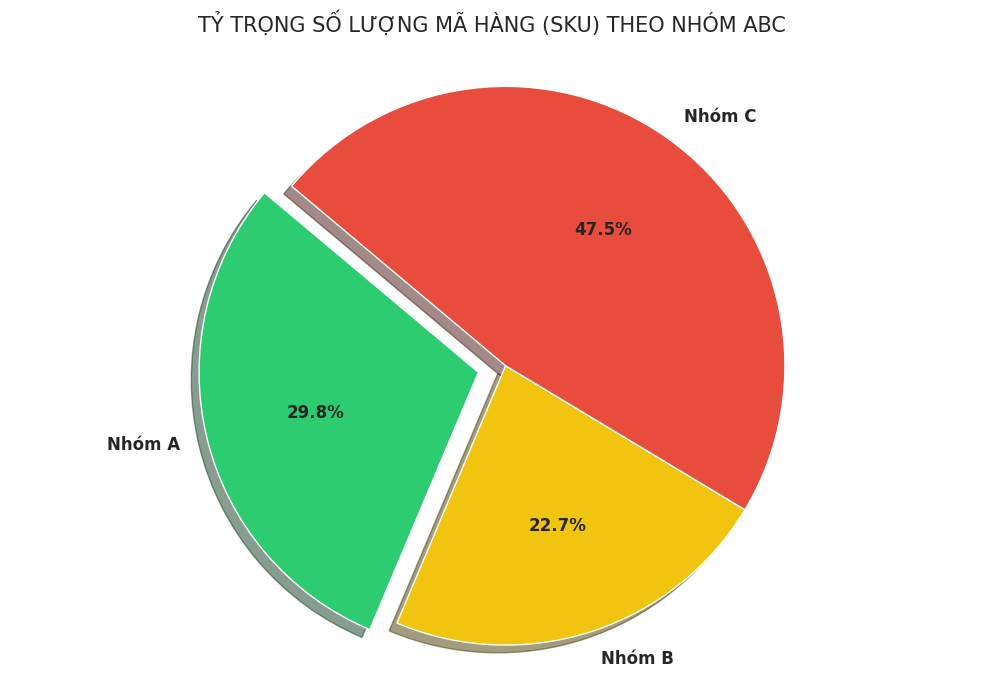

In [ ]:
# --- BIỂU ĐỒ 3: Tỷ trọng số lượng mã hàng (SKU) ---

# 1. Tính toán tần suất SKU sau khi đã phân loại ABC (Kế thừa data từ bước trước)
sku_counts = product_abc['ABC_Rank'].value_counts().reindex(['A', 'B', 'C'])

# 2. Trực quan hóa Biểu đồ tròn
plt.figure(figsize=(10, 7))
colors = ['#2ecc71', '#f1c40f', '#e74c3c'] # A: Xanh lá, B: Vàng, C: Đỏ
explode = (0.1, 0, 0)  # Tách nhẹ miếng bánh nhóm A để tạo điểm nhấn

plt.pie(sku_counts, labels=[f'Nhóm {i}' for i in sku_counts.index],
        autopct='%1.1f%%', startangle=140, colors=colors,
        explode=explode, shadow=True,
        textprops={'fontsize': 12, 'fontweight': 'bold'})

plt.title('TỶ TRỌNG SỐ LƯỢNG MÃ HÀNG (SKU) THEO NHÓM ABC', fontsize=15, pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()

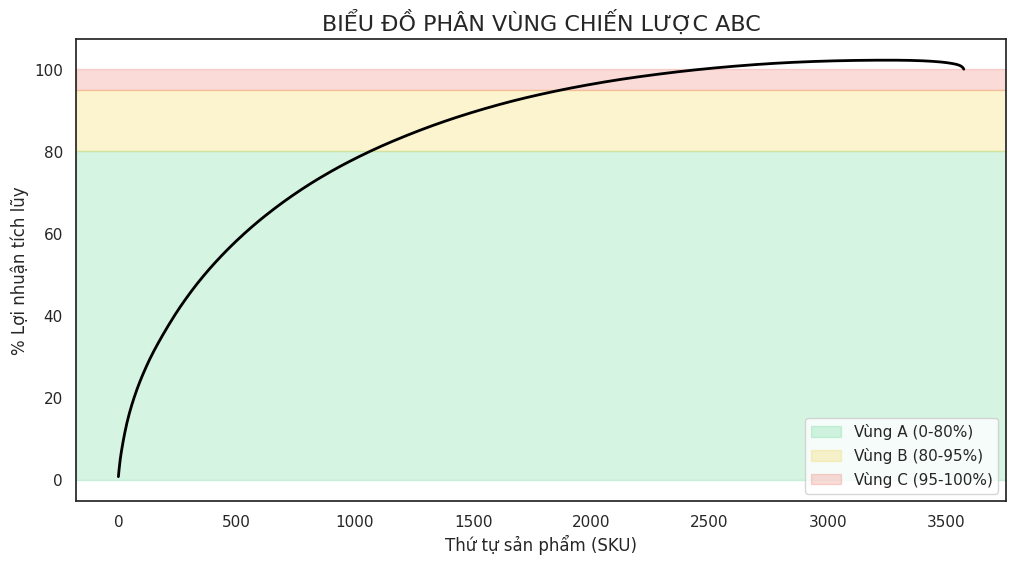

In [ ]:
# --- BIỂU ĐỒ 2: ĐƯỜNG CONG TÍCH LŨY VÀ PHÂN VÙNG CHIẾN LƯỢC ---
plt.figure(figsize=(12, 6))
plt.plot(product_abc.index, product_abc['cum_pct'], color='black', linewidth=2)

# Tô màu nền cho các vùng A, B, C
plt.axhspan(0, 80, color='#2ecc71', alpha=0.2, label='Vùng A (0-80%)')
plt.axhspan(80, 95, color='#f1c40f', alpha=0.2, label='Vùng B (80-95%)')
plt.axhspan(95, 100, color='#e74c3c', alpha=0.2, label='Vùng C (95-100%)')

plt.title('BIỂU ĐỒ PHÂN VÙNG CHIẾN LƯỢC ABC', fontsize=16)
plt.xlabel('Thứ tự sản phẩm (SKU)')
plt.ylabel('% Lợi nhuận tích lũy')
plt.legend()

plt.show()

# **5. Kết quả và Insight từ dữ liệu thực tế**

Dựa trên kết quả chạy code, chúng ta thu được bảng thống kê mật độ sau:

| Nhóm ABC | Số lượng SKU | % Số lượng (SKU) | Tổng Lợi nhuận | % Lợi nhuận đóng góp |
| --- | --- | --- | --- | --- |
| **Nhóm A** | 1,064 | **29.8%** | USD 852,131 | **80%** |
| **Nhóm B** | 813 | 22.7% | USD 159,888 | 15% |
| **Nhóm C** | 1,699 | **47.5%** | USD 53,348 | **5%** |

#### **Phân tích chiến lược:**

1. **Nhóm A (Trọng yếu):** Chỉ chiếm gần **30% danh mục** nhưng gánh vác tới **80% lợi nhuận**. Đây là những sản phẩm như *Herbal Essences Bio* hay *Rose Gold Petal Studs*.
* **Hành động:** Tuyệt đối không để đứt hàng (Out-of-stock). Cần ưu tiên kiểm kho hàng tuần.


2. **Nhóm C (Thứ yếu):** Chiếm tới gần **một nửa kho hàng (47.5%)** nhưng chỉ mang lại **5% lợi nhuận**.
* **Hành động:** Nhóm này đang gây tốn chi phí quản lý và diện tích kho. Cần rà soát để loại bỏ hoặc bán Combo xả hàng để giải phóng diện tích kho cho các mã nhóm A mới.


3. **Tỷ lệ 30/70:** Dữ liệu cho thấy doanh nghiệp này có cấu trúc sản phẩm khá tập trung, sát với quy luật Pareto mở rộng.

# **6. Danh sách Top 5 sản phẩm Nhóm A cần ưu tiên đặc biệt**

| Sản phẩm | Lợi nhuận (USD ) | % Lũy kế |
| --- | --- | --- |
| **Herbal Essences Bio** | USD 9,089 | 0.85% |
| **Rose Gold Petal Studs** | USD 7,400 | 1.55% |
| **Sterling Frost Earrings** | USD 6,071 | 2.12% |
| **Gold Spectrum Anklet** | USD 5,943 | 2.68% |
| **Golden Vine Bracelet** | USD 5,742 | 3.21% |

**Kết luận gửi Giám đốc vận hành:** Chúng ta nên dồn 80% nguồn lực kiểm kê và diện tích kho ở các vị trí thuận tiện nhất cho 1,064 mã hàng thuộc nhóm A. Đồng thời, lên kế hoạch xả kho cho 1,699 mã hàng thuộc nhóm C để tối ưu hóa chi phí vận hành cuối năm.